# Metamodel validation (propagation holdout)

Three steps:

1. **Fit** — `mm.fit(goal)` or `mm.fit_all()`
2. **Validate** — `val.sweep(goal)` for metrics; `val.validate(goal, n=…)` for plotting
3. **Plot** — `result.plot('10m')`, `result.plot_all()`, …

Validation loads saved models only (no refitting). Holdout metrics and plots
include **`hs`, `tp`, `dir`, `spr`** (`spr` via PCA; `tp` raw). Use
`mm.report_training_data(goal, n=450)` or `mm.load_fit_summary(goal, 450)` after
fit to inspect site filter and PCA site retention.

In [1]:
import matplotlib.pyplot as plt
from utils.config import METAMODEL, load_goals, mda_max_points
from utils.evaluation import validation as val
from utils.model import metamodel as mm

In [2]:
goals = list(load_goals().keys())
candidates = METAMODEL["mda_candidates"]
metrics = METAMODEL["validation"]["metrics_variables"]
site_filter = METAMODEL["site_filter"]

print(f"goals      : {goals}")
print(f"candidates : {candidates}")
print(f"metrics    : {metrics}")
print(f"MDA max    : {mda_max_points()} (test cases = 500 - max)")
for key, threshold in site_filter.items():
    if key.endswith("_max"):
        var = key[:-4]
        print(f"{var} filter : > {threshold} removed before PCA (site_filter)")
    elif key.endswith("_min"):
        var = key[:-4]
        print(f"{var} filter : < {threshold} removed before PCA (site_filter)")
print("PCA NaN    : dry-site handling in metamodel.pca_preprocessing (see README)")

goals      : ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16']
candidates : [50, 100, 150, 250, 450]
metrics    : ['hs', 'tp', 'dir', 'spr']
MDA max    : 450 (test cases = 500 - max)
hs filter : > 10.0 removed before PCA (site_filter)
tp filter : < 0.5 removed before PCA (site_filter)
PCA NaN    : dry-site handling in metamodel.pca_preprocessing (see README)


## 1 · Fit

In [3]:
# All goals:
# mm.fit_all(gp_epochs=1500)

## 2 · Validate

In [6]:
# Metrics for every MDA size → outputs/goal_01/validation_metrics.csv
metrics = val.sweep(2)
metrics.head()

2026-07-13 10:53:05,559 - hyglow.validation - INFO - Goal 2: validating n=50
INFO:ExactGPInterpolation:Preprocessing dataset for prediction
INFO:ExactGPInterpolation:Checking for NaNs in subset data
INFO:ExactGPInterpolation:Preprocessing subset data
INFO:ExactGPInterpolation:Normalizing subset data
INFO:ExactGPInterpolation:Proposed max custom scaler for spr is lower than datapoint
INFO:ExactGPInterpolation:Proposed min custom scaler for dir_u is bigger than datapoint
INFO:ExactGPInterpolation:Proposed min custom scaler for dir_v is bigger than datapoint
INFO:ExactGPInterpolation:Proposed max custom scaler for dir_v is lower than datapoint
INFO:ExactGPInterpolation:Subset data preprocessed successfully
INFO:ExactGPInterpolation:Predicting target variable: hs__PC1
INFO:ExactGPInterpolation:Predicting target variable: hs__PC2
INFO:ExactGPInterpolation:Predicting target variable: hs__PC3
INFO:ExactGPInterpolation:Predicting target variable: hs__PC4
INFO:ExactGPInterpolation:Predicting ta

,goal,mda_candidate,n_test_cases,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,r2
0,2,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,hs,Hs,4100,1.393376e-03,0.046712,0.922782
1,2,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,tp,Tp,4100,7.225324e-08,0.000001,1.000000
2,2,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,dir,Dir,4100,-3.802643e-01,15.358922,0.912242
3,2,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,spr,Spr,3700,1.937629e-01,7.431396,0.769214
4,2,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",10m,isobath,10m,hs,Hs,4300,1.766316e-03,0.048327,0.928124


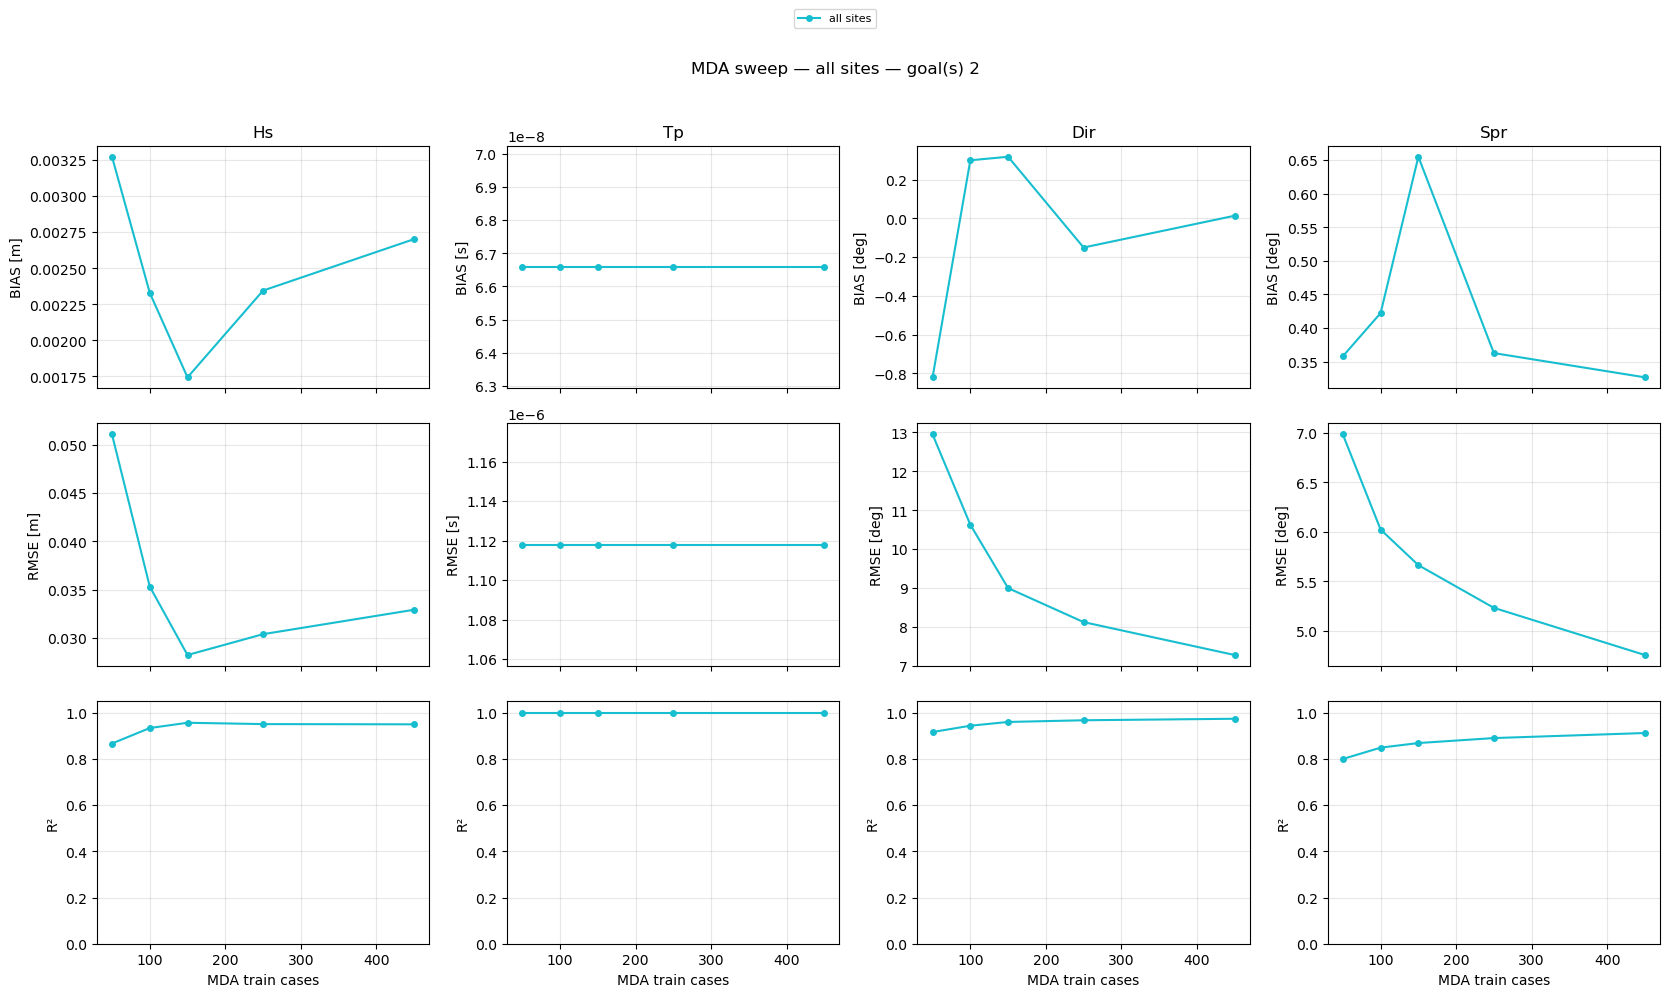

In [7]:
val.plot_sweep(metrics, by="bulk")
plt.show()

## 3 · Plot

In [8]:
n = 450  # MDA size to plot
result = val.validate(2, n)

# Available groups: isobath depths, mesh labels, buoy ids
[g[0] for g in val.metric_groups(result.estimate)]

INFO:ExactGPInterpolation:Preprocessing dataset for prediction
INFO:ExactGPInterpolation:Checking for NaNs in subset data
INFO:ExactGPInterpolation:Preprocessing subset data
INFO:ExactGPInterpolation:Normalizing subset data
INFO:ExactGPInterpolation:Proposed min custom scaler for dir_u is bigger than datapoint
INFO:ExactGPInterpolation:Subset data preprocessed successfully
INFO:ExactGPInterpolation:Predicting target variable: hs__PC1
INFO:ExactGPInterpolation:Predicting target variable: hs__PC2
INFO:ExactGPInterpolation:Predicting target variable: hs__PC3
INFO:ExactGPInterpolation:Predicting target variable: hs__PC4
INFO:ExactGPInterpolation:Predicting target variable: hs__PC5
INFO:ExactGPInterpolation:Predicting target variable: hs__PC6
INFO:ExactGPInterpolation:Predicting target variable: hs__PC7
INFO:ExactGPInterpolation:Predicting target variable: hs__PC8
INFO:ExactGPInterpolation:Predicting target variable: hs__PC9
INFO:ExactGPInterpolation:Predicting target variable: hs__PC10
INF

['5m',
 '10m',
 '20m',
 '50m',
 'Apia',
 'buoy_Apolima_Buoy',
 'buoy_American_Samoa_Buoy',
 'buoy_Aunuu_Buoy']

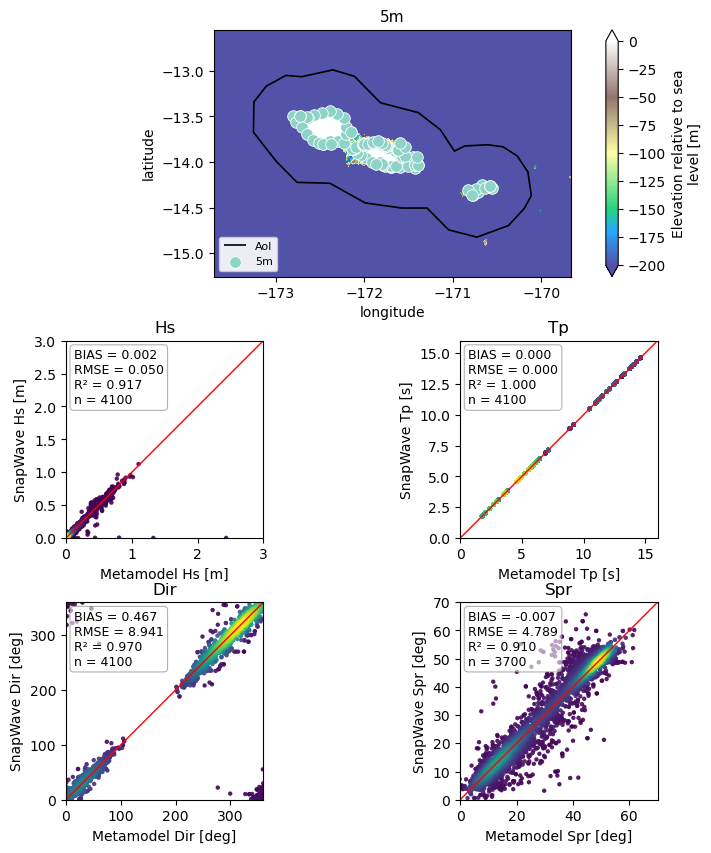

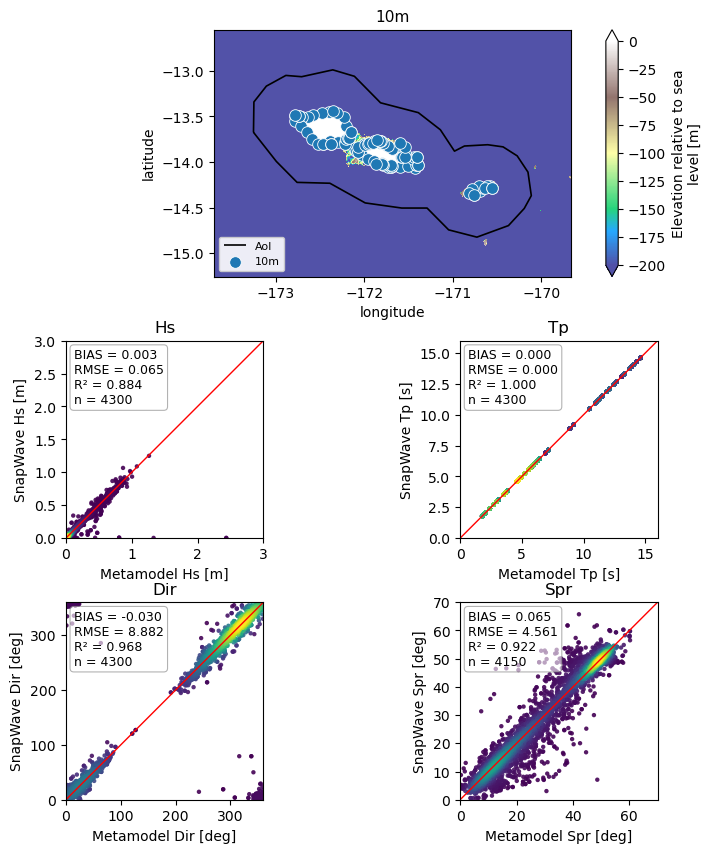

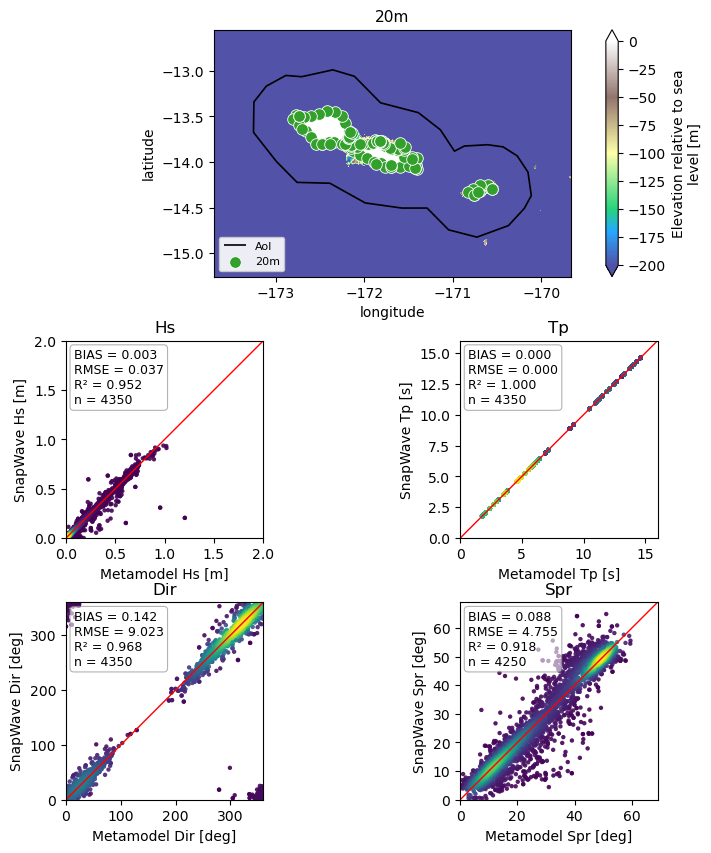

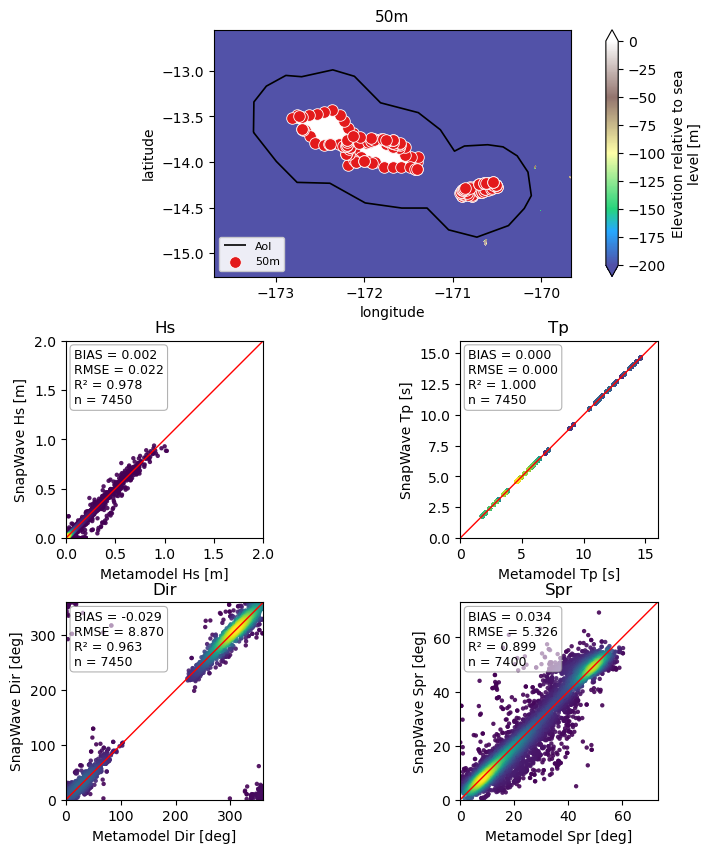

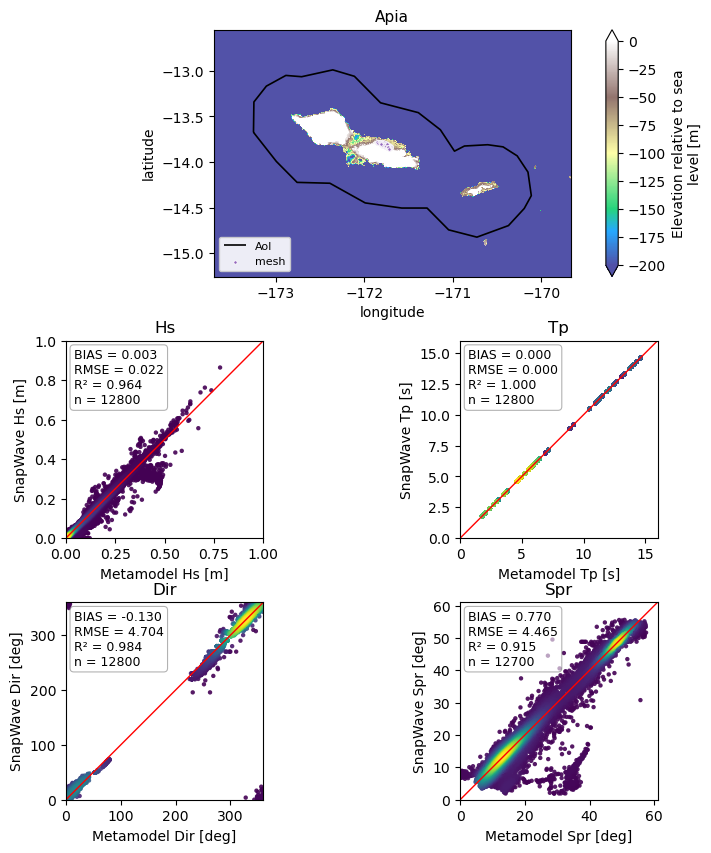

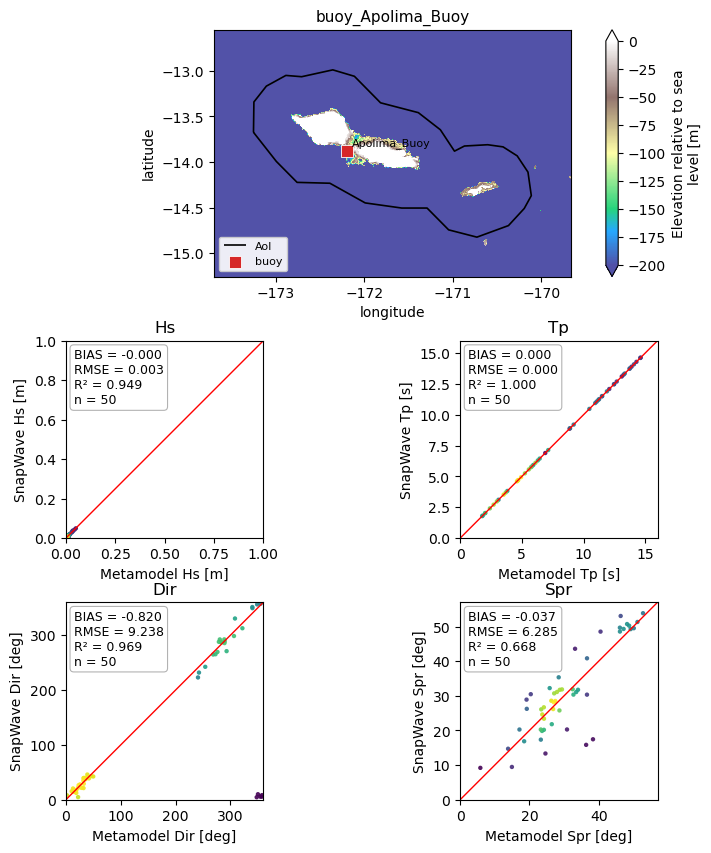

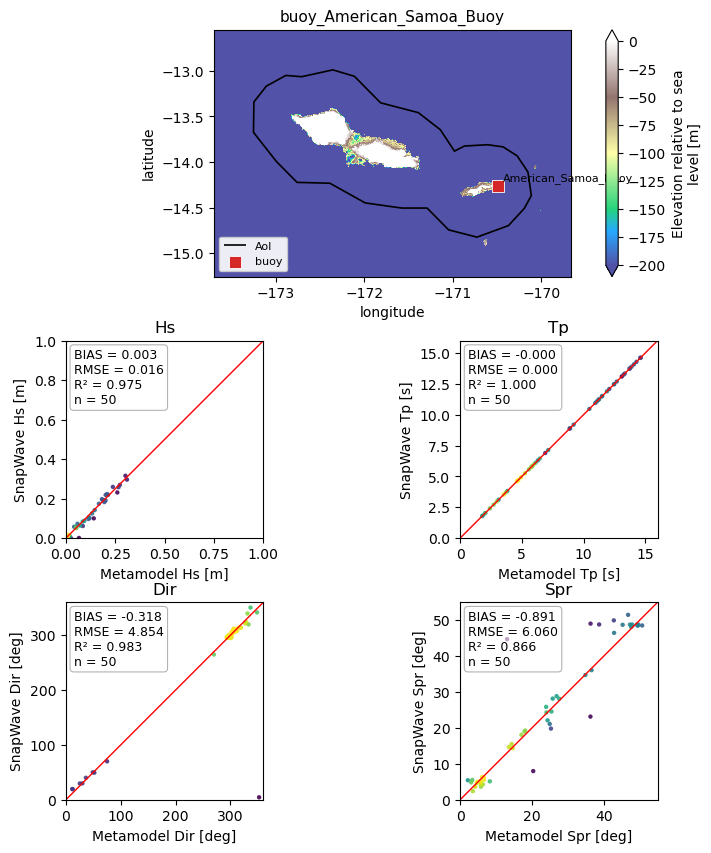

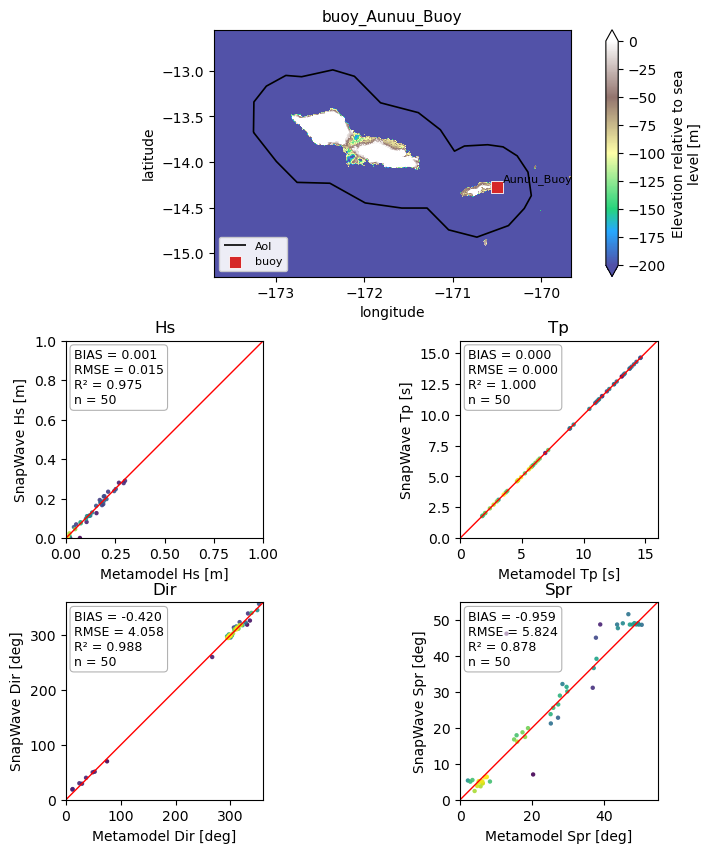

In [9]:
# Map only, or scatters only
# result.plot_map("10m")
# result.plot_scatter("10m", variables=["hs"])

# All groups (optionally filter variables or groups)
for fig in result.plot_all():
    plt.show()

## All goals

In [8]:
all_metrics = val.sweep_all()
all_metrics

2026-07-01 12:56:58,740 - Samoa.validation - INFO - Goal 1: validating n=25
INFO:ExactGPInterpolation:Preprocessing dataset for prediction
INFO:ExactGPInterpolation:Checking for NaNs in subset data
INFO:ExactGPInterpolation:Preprocessing subset data
INFO:ExactGPInterpolation:Normalizing subset data
INFO:ExactGPInterpolation:Proposed max custom scaler for spr is lower than datapoint
INFO:ExactGPInterpolation:Proposed min custom scaler for wl is bigger than datapoint
INFO:ExactGPInterpolation:Proposed max custom scaler for wl is lower than datapoint
INFO:ExactGPInterpolation:Proposed max custom scaler for dir_u is lower than datapoint
INFO:ExactGPInterpolation:Subset data preprocessed successfully
INFO:ExactGPInterpolation:Predicting target variable: hs__PC1
INFO:ExactGPInterpolation:Predicting target variable: hs__PC2
INFO:ExactGPInterpolation:Predicting target variable: hs__PC3
INFO:ExactGPInterpolation:Predicting target variable: hs__PC4
INFO:ExactGPInterpolation:Predicting target var

,goal,mda_candidate,n_test_cases,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,r2
0,1,25,50,"{'hs': 0.99, 'dir': 0.99}",5m,isobath,5m,hs,Hs,4100,-1.338753e-02,8.296481e-02,0.755458
1,1,25,50,"{'hs': 0.99, 'dir': 0.99}",5m,isobath,5m,tp,Tp,4100,1.241373e-08,8.333811e-07,1.000000
2,1,25,50,"{'hs': 0.99, 'dir': 0.99}",5m,isobath,5m,dir,Dir,4100,-3.712451e+00,1.917602e+01,0.900752
3,1,25,50,"{'hs': 0.99, 'dir': 0.99}",10m,isobath,10m,hs,Hs,5000,-8.091528e-03,7.864926e-02,0.742539
4,1,25,50,"{'hs': 0.99, 'dir': 0.99}",10m,isobath,10m,tp,Tp,5000,1.147401e-08,8.223212e-07,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1579,11,450,50,"{'hs': 0.99, 'dir': 0.99}",buoy_American_Samoa_Buoy,buoy,waves,tp,Tp,50,-8.036510e-08,8.025928e-07,1.000000
1580,11,450,50,"{'hs': 0.99, 'dir': 0.99}",buoy_American_Samoa_Buoy,buoy,waves,dir,Dir,50,2.134235e+00,9.008065e+00,0.969275
1581,11,450,50,"{'hs': 0.99, 'dir': 0.99}",buoy_Aunuu_Buoy,buoy,waves,hs,Hs,50,-8.172801e-04,5.377907e-03,0.968523
1582,11,450,50,"{'hs': 0.99, 'dir': 0.99}",buoy_Aunuu_Buoy,buoy,waves,tp,Tp,50,-2.076045e-08,8.330396e-07,1.000000


In [9]:
# Best MDA size per goal (10m isobath, Hs)
hs_10m = all_metrics.query("site_label == 'Apia' and variable == 'hs'")
best = hs_10m.loc[hs_10m.groupby("goal")["rmse"].idxmin()]
best[["goal", "mda_candidate", "site_label", "rmse", "r2", "n"]]

,goal,mda_candidate,site_label,rmse,r2,n
132,1,450,Apia,0.035596,0.916244,9150
1380,10,200,Apia,0.009399,0.942012,9150
1500,11,125,Apia,0.066500,-11.161987,9250
276,2,450,Apia,0.043679,0.956096,9350
420,3,450,Apia,0.040938,0.980284,9350
564,4,450,Apia,0.043150,0.976319,8600
708,5,450,Apia,0.033427,0.976736,9350
852,6,450,Apia,0.034609,0.913641,9350
924,7,125,Apia,0.021667,0.850171,8600
1068,8,125,Apia,0.007777,0.924219,8650
